In [78]:
import ccxt
import pandas as pd
from datetime import datetime, timedelta

def fetch_ohlcv_data(exchange_id='binance', symbol='BTC/USDT', 
                      timeframe='1h', days_back=1095):
    """
    Fetch historical OHLCV data from exchange
    """
    exchange = ccxt.binance({
        'enableRateLimit': True,
    'timeout': 30000} )

    
    since = exchange.parse8601(
        (datetime.now() - timedelta(days=days_back)).isoformat()
    )
    
    all_ohlcv = []
    
    while since < exchange.milliseconds():
        ohlcv = exchange.fetch_ohlcv(symbol, timeframe, since, limit=1000)
        if not ohlcv:
            break
        since = ohlcv[-1][0] + 1
        all_ohlcv.extend(ohlcv)
        
    df = pd.DataFrame(
        all_ohlcv, 
        columns=['timestamp', 'open', 'high', 'low', 'close', 'volume']
    )
    df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
    df.set_index('timestamp', inplace=True)
    
    return df

# Fetch 3 years of hourly Bitcoin data
btc_data = fetch_ohlcv_data()
print(f"Loaded {len(btc_data)} hourly candles")

Loaded 26277 hourly candles


In [52]:
btc_data

,open,high,low,close,volume
timestamp,,,,,
2023-08-31 17:00:00,26234.22,26400.43,26133.94,26329.07,4324.91773
2023-08-31 18:00:00,26329.08,26387.32,26189.77,26292.23,1827.46445
2023-08-31 19:00:00,26292.24,26319.40,25928.00,26162.79,4521.91272
2023-08-31 20:00:00,26162.79,26194.86,25959.72,26022.61,2429.77606
2023-08-31 21:00:00,26022.61,26037.97,25655.01,26024.57,4573.05529
...,...,...,...,...,...
2026-08-30 09:00:00,78074.01,78118.87,77986.00,78000.01,165.26795
2026-08-30 10:00:00,78000.01,78145.29,77962.49,78145.29,168.30514
2026-08-30 11:00:00,78145.29,78242.00,78117.11,78166.00,172.04094


In [79]:
btc_data.reset_index(inplace=True)
btc_data
# btc_data = btc_data.drop('index', axis = 1)
# btc_data = btc_data.drop('level_0', axis = 1)

,timestamp,open,high,low,close,volume
0,2023-08-31 17:00:00,26234.22,26400.43,26133.94,26329.07,4324.91773
1,2023-08-31 18:00:00,26329.08,26387.32,26189.77,26292.23,1827.46445
2,2023-08-31 19:00:00,26292.24,26319.40,25928.00,26162.79,4521.91272
3,2023-08-31 20:00:00,26162.79,26194.86,25959.72,26022.61,2429.77606
4,2023-08-31 21:00:00,26022.61,26037.97,25655.01,26024.57,4573.05529
...,...,...,...,...,...,...
26272,2026-08-30 09:00:00,78074.01,78118.87,77986.00,78000.01,165.26795
26273,2026-08-30 10:00:00,78000.01,78145.29,77962.49,78145.29,168.30514
26274,2026-08-30 11:00:00,78145.29,78242.00,78117.11,78166.00,172.04094
26275,2026-08-30 12:00:00,78165.99,78850.81,78165.99,78785.06,814.10982


In [80]:
btc_data['date'] = pd.to_datetime(btc_data['timestamp'], unit='ms')
btc_data.drop('timestamp', axis = 1, inplace=True)
btc_data

,open,high,low,close,volume,date
0,26234.22,26400.43,26133.94,26329.07,4324.91773,2023-08-31 17:00:00
1,26329.08,26387.32,26189.77,26292.23,1827.46445,2023-08-31 18:00:00
2,26292.24,26319.40,25928.00,26162.79,4521.91272,2023-08-31 19:00:00
3,26162.79,26194.86,25959.72,26022.61,2429.77606,2023-08-31 20:00:00
4,26022.61,26037.97,25655.01,26024.57,4573.05529,2023-08-31 21:00:00
...,...,...,...,...,...,...
26272,78074.01,78118.87,77986.00,78000.01,165.26795,2026-08-30 09:00:00
26273,78000.01,78145.29,77962.49,78145.29,168.30514,2026-08-30 10:00:00
26274,78145.29,78242.00,78117.11,78166.00,172.04094,2026-08-30 11:00:00
26275,78165.99,78850.81,78165.99,78785.06,814.10982,2026-08-30 12:00:00


In [101]:
# Data Splitting
train = btc_data[btc_data['date'].dt.year <= 2025]
test = btc_data[btc_data['date'].dt.year >= 2025]

In [102]:
len(train), len(test)

(20081, 14558)

In [103]:
import numpy as np

# Adding Close_Shift Variable 
train['close_shift'] = train['close'].shift(1)
test['close_shift'] = test['close'].shift(1)

# Adding Daily Returns variable 
train['return'] = (train['close']/train['close_shift'] - 1) * 100
test['return'] = (test['close']/test['close_shift'] - 1) * 100

# Creating target variable on both datasets
train['target'] = np.where(train['return'].shift(-1) > 0, 1, 0)
test['target'] = np.where(test['return'].shift(-1) > 0, 1, 0)

In [104]:
import ta

# Defining feature engineering function
def engineer_features(df):
    
    # Adding Simple Moving Averages
    df['sma5'] = ta.trend.sma_indicator(df['close'],window = 5)
    df['sma10'] = ta.trend.sma_indicator(df['close'],window = 10)
    df['sma15'] = ta.trend.sma_indicator(df['close'],window = 15)
    df['sma20'] = ta.trend.sma_indicator(df['close'],window = 20)
    df['sma30'] = ta.trend.sma_indicator(df['close'],window = 30)
    df['sma50'] = ta.trend.sma_indicator(df['close'],window = 50)
    df['sma80'] = ta.trend.sma_indicator(df['close'],window = 80)
    df['sma100'] = ta.trend.sma_indicator(df['close'],window = 100)
    df['sma200'] = ta.trend.sma_indicator(df['close'],window = 200)
    
    # Adding Price to Simple Moving Averages ratios

    df['sma5_ratio'] = df['close'] / df['sma5']
    df['sma10_ratio'] = df['close'] / df['sma10']
    df['sma20_ratio'] = df['close'] / df['sma20']
    df['sma30_ratio'] = df['close'] / df['sma30'] 
    df['sma50_ratio'] = df['close'] / df['sma50']
    df['sma80_ratio'] = df['close'] / df['sma80']
    df['sma100_ratio'] = df['close'] / df['sma100']
    df['sma200_ratio'] = df['close'] / df['sma200']

    # Adding RSI, CCI, Bollinger Bands, and OBV

    df['rsi'] = ta.momentum.RSIIndicator(df['close']).rsi()
    df['cci'] = ta.trend.cci(df['high'], df['low'], df['close'], window=20, constant=0.015)
    bb_indicator = ta.volatility.BollingerBands(df['close'])
    df['bb_high'] = bb_indicator.bollinger_hband()
    df['bb_low'] = bb_indicator.bollinger_lband()
    df['obv'] = ta.volume.OnBalanceVolumeIndicator(close=df['close'], volume=df['volume']).on_balance_volume()

    # Adding features derived from the indicators above

    df['rsi_overbought'] = (df['rsi'] >= 70).astype(int)
    df['rsi_oversold'] = (df['rsi'] <= 30).astype(int)
    df['above_bb_high'] = (df['close'] >= df['bb_high']).astype(int)
    df['below_bb_low'] = (df['close'] <= df['bb_low']).astype(int)
    df['obv_divergence_10_days'] = df['obv'].diff().rolling(10).sum() - df['close'].diff().rolling(10).sum()
    df['obv_divergence_20_days'] = df['obv'].diff().rolling(20).sum() - df['close'].diff().rolling(20).sum()
    df['cci_high'] = (df['cci'] >= 120).astype(int)
    df['cci_low'] = (df['cci'] <= -120).astype(int)
    df['sma5 > sma10'] = (df['sma5'] > df['sma10']).astype(int)
    df['sma10 > sma15'] = (df['sma10'] > df['sma15']).astype(int)
    df['sma15 > sma20'] = (df['sma15'] > df['sma20']).astype(int)
    df['sma20 > sma30'] = (df['sma20'] > df['sma30']).astype(int)
    df['sma30 > sma50'] = (df['sma30'] > df['sma50']).astype(int)
    df['sma50 > sma80'] = (df['sma50'] > df['sma80']).astype(int)
    df['sma80 > sma100'] = (df['sma80'] > df['sma100']).astype(int)
    df['sma100 > sma200'] = (df['sma100'] > df['sma200']).astype(int)

    # Removing NaN values from the dataframe 
    df.dropna(inplace = True)
    return df

btc_data = engineer_features(btc_data)

In [105]:
# Applying function to the X_train and X_test sets 
train = engineer_features(train)
test = engineer_features(test)

In [106]:
y_train = train['target']
X_train = train.drop('target', axis = 1) 

y_test = test['target']
X_test = test.drop('target', axis = 1) 

In [107]:
X_test = X_test.drop('date', axis = 1) 
X_train = X_train.drop('date', axis = 1) 

In [108]:
print(f'X_train : {len(X_train)}  y_train {len(y_train)} ')
print(f'X_train : {len(X_test)}  y_train {len(y_test)} ')

X_train : 19882  y_train 19882 
X_train : 14359  y_train 14359 


In [109]:
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

classifiers = [CatBoostClassifier(random_state = 42, verbose = False)]

#  Iteraring over classifiers in the list above, training, and evaluating them
for clf in classifiers:
    clf.fit(X_train, y_train)
    y_pred = clf.predict_proba(X_test)[:,1]
    auc_score = roc_auc_score(y_test, y_pred)
    print(f'{type(clf).__name__}: AUC Score={auc_score:.3f}')

CatBoostClassifier: AUC Score=0.673



 Model AUC Score = 0.673 



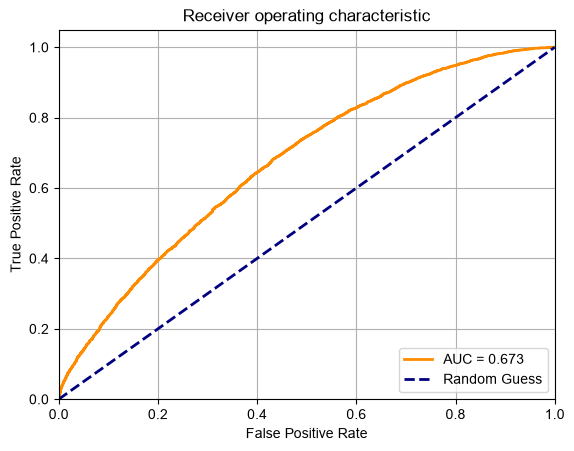

In [110]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt

y_pred = classifiers[0].predict_proba(X_test)[:,1]
auc_score = roc_auc_score(y_test, y_pred)
print(f'\n Model AUC Score = {auc_score:.3f} \n')

# Plotting AUC-ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
auc_score = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc_score:.3f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label = 'Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.style.use('seaborn-v0_8-dark')
plt.grid(True)
plt.show()

In [ ]:

class MeanReversionStrategy:
    def __init__(self, stop_loss=0.03, target_return=0.02, max_hold_hours=48):
        self.stop_loss = stop_loss
        self.target_return = target_return
        self.max_hold_hours = max_hold_hours
        self.position = None
        self.entry_price = None
        self.entry_time = None
        
    def generate_signals(self, df):
        """
        Generate trading signals based on strategy rules
        """
        signals = pd.DataFrame(index=df.index)
        signals['signal'] = 0
        
        # Long entry conditions
        
        entry_condition = (
            (df['bb_position'] < 0.1) &
            (df['volatility_spike'] > 1.5) &
            (df['volume_ratio'] > 1.3) &
            (df['returns_zscore'] < -2)
        )
        
        signals.loc[entry_condition, 'signal'] = 1
        
        return signals
    
    def backtest(self, df):
        """
        Backtest strategy with realistic execution assumptions
        """
        signals = self.generate_signals(df)
        
        positions = []
        trades = []
        
        for i in range(len(df)):
            current_time = df.index[i]
            current_price = df.iloc[i]['close']
            
            # Check if we have an open position
            if self.position is not None:
                hours_held = (current_time - self.entry_time).total_seconds() / 3600
                pnl_pct = (current_price - self.entry_price) / self.entry_price
                
                # Exit conditions
                exit_signal = False
                exit_reason = None
                
                # Stop loss
                if pnl_pct <= -self.stop_loss:
                    exit_signal = True
                    exit_reason = 'stop_loss'
                
                # Target reached (price returned to MA)
                elif current_price >= df.iloc[i]['price_ma_50']:
                    exit_signal = True
                    exit_reason = 'target_reached'
                
                # Maximum hold period
                elif hours_held >= self.max_hold_hours:
                    exit_signal = True
                    exit_reason = 'max_hold'
                
                if exit_signal:
                    trades.append({
                        'entry_time': self.entry_time,
                        'exit_time': current_time,
                        'entry_price': self.entry_price,
                        'exit_price': current_price,
                        'pnl_pct': pnl_pct,
                        'hold_hours': hours_held,
                        'exit_reason': exit_reason
                    })
                    self.position = None
                    self.entry_price = None
                    self.entry_time = None
            
            # Check for new entry signal (only if not in position)
            elif signals.iloc[i]['signal'] == 1:
                self.position = 'long'
                self.entry_price = current_price
                self.entry_time = current_time
            
            positions.append(1 if self.position else 0)
        
        return pd.DataFrame(trades)

# Run backtest
strategy = MeanReversionStrategy()
trades_df = strategy.backtest(btc_data)

print(f"Total trades: {len(trades_df)}")
print(f"Win rate: {(trades_df['pnl_pct'] > 0).mean():.2%}")
print(f"Average return: {trades_df['pnl_pct'].mean():.2%}")

In [3]:
class MeanReversionStrategy:
    def __init__(self, stop_loss=0.03, target_return=0.02, max_hold_hours=48):
        self.stop_loss = stop_loss
        self.target_return = target_return
        self.max_hold_hours = max_hold_hours
        self.position = None
        self.entry_price = None
        self.entry_time = None
        
    def generate_signals(self, df):
        """
        Generate trading signals based on strategy rules
        """
        signals = pd.DataFrame(index=df.index)
        signals['signal'] = 0
        
        # Long entry conditions
        entry_condition = (
            (df['bb_position'] < 0.1) &
            (df['volatility_spike'] > 1.5) &
            (df['volume_ratio'] > 1.3) &
            (df['returns_zscore'] < -2)
        )
        
        signals.loc[entry_condition, 'signal'] = 1
        
        return signals
    
    def backtest(self, df):
        """
        Backtest strategy with realistic execution assumptions
        """
        signals = self.generate_signals(df)
        
        positions = []
        trades = []
        
        for i in range(len(df)):
            current_time = df.index[i]
            current_price = df.iloc[i]['close']
            
            # Check if we have an open position
            if self.position is not None:
                hours_held = (current_time - self.entry_time).total_seconds() / 3600
                pnl_pct = (current_price - self.entry_price) / self.entry_price
                
                # Exit conditions
                exit_signal = False
                exit_reason = None
                
                # Stop loss
                if pnl_pct <= -self.stop_loss:
                    exit_signal = True
                    exit_reason = 'stop_loss'
                
                # Target reached (price returned to MA)
                elif current_price >= df.iloc[i]['price_ma_50']:
                    exit_signal = True
                    exit_reason = 'target_reached'
                
                # Maximum hold period
                elif hours_held >= self.max_hold_hours:
                    exit_signal = True
                    exit_reason = 'max_hold'
                
                if exit_signal:
                    trades.append({
                        'entry_time': self.entry_time,
                        'exit_time': current_time,
                        'entry_price': self.entry_price,
                        'exit_price': current_price,
                        'pnl_pct': pnl_pct,
                        'hold_hours': hours_held,
                        'exit_reason': exit_reason
                    })
                    self.position = None
                    self.entry_price = None
                    self.entry_time = None
            
            # Check for new entry signal (only if not in position)
            elif signals.iloc[i]['signal'] == 1:
                self.position = 'long'
                self.entry_price = current_price
                self.entry_time = current_time
            
            positions.append(1 if self.position else 0)
        
        return pd.DataFrame(trades)

# Run backtest
strategy = MeanReversionStrategy()
trades_df = strategy.backtest(btc_data)

print(f"Total trades: {len(trades_df)}")
print(f"Win rate: {(trades_df['pnl_pct'] > 0).mean():.2%}")
print(f"Average return: {trades_df['pnl_pct'].mean():.2%}")

Total trades: 86
Win rate: 59.30%
Average return: -0.11%


In [5]:
def analyze_performance(trades_df, initial_capital=10000, 
                         trading_fee=0.001, slippage=0.0005):
    """
    Calculate realistic returns accounting for costs
    """
    # Apply transaction costs
    trades_df['gross_pnl_pct'] = trades_df['pnl_pct']
    trades_df['fees'] = trading_fee * 2  # Entry + exit
    trades_df['slippage_cost'] = slippage * 2
    trades_df['net_pnl_pct'] = (
        trades_df['gross_pnl_pct'] - 
        trades_df['fees'] - 
        trades_df['slippage_cost']
    )
    
    # Calculate metrics
    metrics = {
        'total_trades': len(trades_df),
        'win_rate': (trades_df['net_pnl_pct'] > 0).mean(),
        'avg_return': trades_df['net_pnl_pct'].mean(),
        'median_return': trades_df['net_pnl_pct'].median(),
        'best_trade': trades_df['net_pnl_pct'].max(),
        'worst_trade': trades_df['net_pnl_pct'].min(),
        'sharpe_ratio': trades_df['net_pnl_pct'].mean() / trades_df['net_pnl_pct'].std() if len(trades_df) > 0 else 0,
        'profit_factor': abs(trades_df[trades_df['net_pnl_pct'] > 0]['net_pnl_pct'].sum() / 
                            trades_df[trades_df['net_pnl_pct'] < 0]['net_pnl_pct'].sum()) if (trades_df['net_pnl_pct'] < 0).any() else float('inf')
    }
    
    # Portfolio simulation
    portfolio_value = initial_capital
    equity_curve = [portfolio_value]
    
    for pnl in trades_df['net_pnl_pct']:
        portfolio_value *= (1 + pnl)
        equity_curve.append(portfolio_value)
    
    # Drawdown analysis
    equity_series = pd.Series(equity_curve)
    rolling_max = equity_series.expanding().max()
    drawdown = (equity_series - rolling_max) / rolling_max
    
    metrics['max_drawdown'] = drawdown.min()
    metrics['final_capital'] = portfolio_value
    metrics['total_return'] = (portfolio_value - initial_capital) / initial_capital
    
    return metrics, equity_curve

metrics, equity_curve = analyze_performance(trades_df)

print("\n=== Strategy Performance ===")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")


=== Strategy Performance ===
total_trades: 86
win_rate: 0.5581
avg_return: -0.0041
median_return: 0.0023
best_trade: 0.0744
worst_trade: -0.0654
sharpe_ratio: -0.1369
profit_factor: 0.7079
max_drawdown: -0.3932
final_capital: 6776.1419
total_return: -0.3224


In [6]:
def analyze_performance(trades_df, initial_capital=10000, 
                         trading_fee=0.001, slippage=0.0005):
    """
    Calculate realistic returns accounting for costs
    """
    # Apply transaction costs
    trades_df['gross_pnl_pct'] = trades_df['pnl_pct']
    trades_df['fees'] = trading_fee * 2  # Entry + exit
    trades_df['slippage_cost'] = slippage * 2
    trades_df['net_pnl_pct'] = (
        trades_df['gross_pnl_pct'] - 
        trades_df['fees'] - 
        trades_df['slippage_cost']
    )
    
    # Calculate metrics
    metrics = {
        'total_trades': len(trades_df),
        'win_rate': (trades_df['net_pnl_pct'] > 0).mean(),
        'avg_return': trades_df['net_pnl_pct'].mean(),
        'median_return': trades_df['net_pnl_pct'].median(),
        'best_trade': trades_df['net_pnl_pct'].max(),
        'worst_trade': trades_df['net_pnl_pct'].min(),
        'sharpe_ratio': trades_df['net_pnl_pct'].mean() / trades_df['net_pnl_pct'].std() if len(trades_df) > 0 else 0,
        'profit_factor': abs(trades_df[trades_df['net_pnl_pct'] > 0]['net_pnl_pct'].sum() / 
                            trades_df[trades_df['net_pnl_pct'] < 0]['net_pnl_pct'].sum()) if (trades_df['net_pnl_pct'] < 0).any() else float('inf')
    }
    
    # Portfolio simulation
    portfolio_value = initial_capital
    equity_curve = [portfolio_value]
    
    for pnl in trades_df['net_pnl_pct']:
        portfolio_value *= (1 + pnl)
        equity_curve.append(portfolio_value)
    
    # Drawdown analysis
    equity_series = pd.Series(equity_curve)
    rolling_max = equity_series.expanding().max()
    drawdown = (equity_series - rolling_max) / rolling_max
    
    metrics['max_drawdown'] = drawdown.min()
    metrics['final_capital'] = portfolio_value
    metrics['total_return'] = (portfolio_value - initial_capital) / initial_capital
    
    return metrics, equity_curve

metrics, equity_curve = analyze_performance(trades_df)

print("\n=== Strategy Performance ===")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")


=== Strategy Performance ===
total_trades: 86
win_rate: 0.5581
avg_return: -0.0041
median_return: 0.0023
best_trade: 0.0744
worst_trade: -0.0654
sharpe_ratio: -0.1369
profit_factor: 0.7079
max_drawdown: -0.3932
final_capital: 6776.1419
total_return: -0.3224


In [7]:
def walk_forward_analysis(df, train_period_months=18, test_period_months=6):
    """
    Walk-forward optimization to prevent overfitting
    """
    results = []
    
    # Split data into train/test windows
    total_months = len(df) // (30 * 24)  # Approximate months
    num_windows = (total_months - train_period_months) // test_period_months
    
    for i in range(num_windows):
        train_start_idx = i * test_period_months * 30 * 24
        train_end_idx = train_start_idx + train_period_months * 30 * 24
        test_end_idx = train_end_idx + test_period_months * 30 * 24
        
        train_data = df.iloc[train_start_idx:train_end_idx]
        test_data = df.iloc[train_end_idx:test_end_idx]
        
        # Train strategy on training period
        strategy = MeanReversionStrategy()
        
        # Test on out-of-sample period
        test_trades = strategy.backtest(test_data)
        
        if len(test_trades) > 0:
            test_metrics, _ = analyze_performance(test_trades)
            results.append({
                'window': i,
                'test_period_start': test_data.index[0],
                'test_period_end': test_data.index[-1],
                'trades': len(test_trades),
                'win_rate': test_metrics['win_rate'],
                'avg_return': test_metrics['avg_return'],
                'sharpe': test_metrics['sharpe_ratio']
            })
    
    return pd.DataFrame(results)

# Perform walk-forward analysis
wf_results = walk_forward_analysis(btc_data)
print("\n=== Walk-Forward Analysis ===")
print(wf_results)
print(f"\nConsistent win rate: {wf_results['win_rate'].mean():.2%}")
print(f"Win rate std dev: {wf_results['win_rate'].std():.2%}")


=== Walk-Forward Analysis ===
   window   test_period_start     test_period_end  trades  win_rate  \
0       0 2025-02-19 14:00:00 2025-08-18 13:00:00      11  0.636364   
1       1 2025-08-18 14:00:00 2026-02-14 13:00:00      15  0.466667   
2       2 2026-02-14 14:00:00 2026-08-13 13:00:00      15  0.666667   

   avg_return    sharpe  
0   -0.000961 -0.027519  
1   -0.010552 -0.453447  
2    0.001052  0.040463  

Consistent win rate: 58.99%
Win rate std dev: 10.78%
